[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_14/MFM_ch14_virtue_complexity/MFM_ch14_virtue_complexity.ipynb)

# MFM_ch14_virtue_complexity

Case study, Kelly, Malamud and Zhou (2024), The virtue of complexity in return prediction, on course data: monthly SPY excess returns and seven Welch-Goyal predictors (tbl, lty, tms, dfy, infl, svar, lagged return), random Fourier features with gamma = 2, ridge without intercept on rolling windows of 12 complete observations, P = 2 to 12,000, log10 z = -3 to 3, statistics of each draw averaged over 1,000 draws; out-of-sample R-squared (1 - forecast-error variance over return variance) and Sharpe ratio of the timing strategy against complexity c = P/T, linear kitchen-sink benchmarks and the timing position with NBER recessions.

In the displayed course-data results, the highest-complexity RFF specification (c=1000, z=1000) has R-squared about -6.68% and annualised Sharpe about 0.074, versus 0.25% and 0.317 for the linear shrinkage benchmark. This sample does not show that greater complexity automatically improves prediction. The RFF table averages each draw's statistics; the position chart instead averages positions across draws. r2 is in percent; sr and ir are annualised; maxloss measures the largest monthly loss in units of the strategy-return standard deviation. ir_lin and ir_lin_t are only applicable to the RFF comparison against the linear benchmark, so the linear rows show NaN. The recession summary covers three episodes. The complete R-squared and Sharpe grids below disclose all values, including troughs hidden by the explicitly labelled -60% plot limit.

*Modelling Financial Markets (MFM), Chapter 14: Deep Learning and Time-Series Foundation Models. Author: Daniel Traian Pele.*

Calendar convention: form the next-month target and trailing 12-calendar-month scaling before removing incomplete rows. Missing CPI months are not interpolated. Each ridge training window contains the previous 12 complete observations; across missing data, it can span more than 12 calendar months.


> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_14'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261017T011801-c9fb41


In [ ]:
import os
import sys
import json
import time
import subprocess
for pkg, mod in (('arch', 'arch'), ('chronos-forecasting', 'chronos'), ('timesfm', 'timesfm')):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import torch
import warnings
warnings.filterwarnings('ignore')

## Data, models and tests

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of data/market when the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

# name -> (symbol, start date); indices and crypto: closing price
SOURCES = {'sp500': ('GSPC.INDX', '1990-01-01'), 'btc': ('BTC-USD.CC', '2014-09-17'), 'bet': ('BET', '1997-09-19')}
LABELS = {'sp500': 'S&P 500', 'btc': 'Bitcoin', 'bet': 'BET'}
ASSETS = list(SOURCES)
TEST_FROM = {'sp500': '2016-01-01', 'btc': '2019-01-01', 'bet': '2016-01-01'}
POST_FROM = '2025-11-03'   # chosen common cutoff: first Monday after the weights of all three foundation models were public
CTX = 512                  # context length (observations) for the foundation models
W = 1000                   # estimation window for HS, GARCH-t, FHS
REFIT = 20                 # GARCH parameters re-estimated every 20 days
A_VAR, A_ES = 0.01, 0.025  # VaR 1%, ES 2.5%
FM_NAMES = {'chronos2': 'Chronos-2', 'bolt': 'Chronos-Bolt', 'timesfm': 'TimesFM-2.5'}
FM_REPO = {'chronos2': 'amazon/chronos-2', 'bolt': 'amazon/chronos-bolt-small',
           'timesfm': 'google/timesfm-2.5-200m-pytorch'}
C2_LEVELS = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
             0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
DEC_LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


# =============================================================================
# DATA
# =============================================================================
def read_market(symbol):
    """Read data/market/<SYMBOL>.csv locally or from the GitHub repository."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_returns(name):
    """Daily log returns in %, on the series' own calendar."""
    symbol, start = SOURCES[name]
    p = read_market(symbol)['close'].loc[start:]
    p = p[p > 0].dropna()
    return (100 * np.log(p).diff()).dropna().rename(LABELS[name])


def load_rv():
    """Daily realised variance of SPY (regular session, 5-minute returns, %^2)."""
    fname = 'intraday/SPY.US_5m.csv'
    path = os.path.join(MARKET_DIR, fname)
    d = pd.read_csv(path if os.path.exists(path) else REPO_RAW + fname, parse_dates=['datetime_utc'])
    d['day'] = d['datetime_utc'].dt.normalize()
    d['r'] = 100 * np.log(d['close']).groupby(d['day']).diff()
    rv = (d['r'] ** 2).groupby(d['day']).sum()
    n = d.groupby('day').size()
    rv = rv[n >= 70]                       # drop shortened trading days
    rv.index = rv.index.tz_localize(None) if rv.index.tz is not None else rv.index
    rv.name = 'RV'
    return rv


def load_spy_daily():
    """Daily close-to-close returns of SPY (%, adjusted price)."""
    p = read_market('SPY.US')['adjusted_close']
    return (100 * np.log(p).diff()).dropna().rename('SPY')


# =============================================================================
# FOUNDATION MODELS (zero-shot)
# =============================================================================
_FM = {}


def load_fm(name):
    """Load a foundation model once (CPU)."""
    if name in _FM:
        return _FM[name]
    import torch
    if name in ('chronos2', 'bolt'):
        from chronos import BaseChronosPipeline
        _FM[name] = BaseChronosPipeline.from_pretrained(FM_REPO[name], device_map='cpu', torch_dtype=torch.float32)
    elif name == 'timesfm':
        import timesfm
        m = timesfm.TimesFM_2p5_200M_torch.from_pretrained(FM_REPO[name])
        m.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=128, normalize_inputs=True,
                                         use_continuous_quantile_head=True, force_flip_invariance=True,
                                         infer_is_positive=False, fix_quantile_crossing=True,
                                         per_core_batch_size=128))
        _FM[name] = m
    else:
        raise ValueError(name)
    return _FM[name]


def fm_forecast(name, contexts, batch=256):
    """One-day-ahead forecast for a list of contexts (1D np.array).
    Returns (levels, Q, point): Q = n x len(levels) matrix of quantiles, point = point forecast
    (the median for all three models: TimesFM-2.5 returns channel 5 of its output, the median)."""
    import torch
    m = load_fm(name)
    Qs, P = [], []
    for i in range(0, len(contexts), batch):
        cb = [np.asarray(c, dtype='float32') for c in contexts[i:i + batch]]
        if name == 'chronos2':
            q, _ = m.predict_quantiles([torch.tensor(c)[None, :] for c in cb], prediction_length=1,
                                       quantile_levels=C2_LEVELS)
            Q = np.stack([qi[0, 0].numpy() for qi in q])
            Qs.append(Q)
            P.append(Q[:, C2_LEVELS.index(0.5)])
        elif name == 'bolt':
            L = max(len(c) for c in cb)
            x = torch.full((len(cb), L), float('nan'))
            for j, c in enumerate(cb):
                x[j, L - len(c):] = torch.tensor(c)
            q, _ = m.predict_quantiles(x, prediction_length=1, quantile_levels=DEC_LEVELS)
            Q = q[:, 0, :].numpy()
            Qs.append(Q)
            P.append(Q[:, DEC_LEVELS.index(0.5)])
        else:
            pf, qf = m.forecast(horizon=1, inputs=cb)
            Qs.append(np.asarray(qf)[:, 0, 1:10])
            P.append(np.asarray(pf)[:, 0])
    levels = C2_LEVELS if name == 'chronos2' else DEC_LEVELS
    return levels, np.vstack(Qs), np.concatenate(P)


def contexts_at(x, origins, ctx=CTX):
    """The context x[t-ctx:t] for each origin t (position in x)."""
    x = np.asarray(x, float)
    return [x[max(0, t - ctx):t] for t in origins]


def quantile_at(levels, Q, u):
    """Quantile of level u by linear interpolation between the available levels; outside the grid:
    the end value (the model gives no more extreme quantiles)."""
    lv = np.asarray(levels)
    return np.array([np.interp(u, lv, row) for row in Q])


def grid_mean(levels, Q, g=lambda v: v):
    """Approximation of E[g(Y)] = integral of g(q_u) over [0, 1], with q_u linear between levels and constant
    outside the grid (understates the tails)."""
    lv = np.r_[0.0, levels, 1.0]
    G = g(np.column_stack([Q[:, :1], Q, Q[:, -1:]]))
    return np.trapezoid(G, lv, axis=1)


def es_from_grid(levels, Q, a=A_ES, n=200):
    """ES_a = -(1/a) * integral_0^a q_u du on the model grid (below the lowest level: constant)."""
    u = (np.arange(n) + 0.5) / n * a
    return -np.mean(np.column_stack([quantile_at(levels, Q, ui) for ui in u]), axis=1)


# =============================================================================
# BASELINE MODELS FOR RETURNS
# =============================================================================
def hist_mean(r, origins):
    x = np.asarray(r, float)
    cs = np.r_[0, np.cumsum(x)]
    return np.array([cs[t] / t for t in origins])


def ar1(r, origins, w=W):
    """AR(1) estimated by OLS on a rolling window of w observations."""
    x = np.asarray(r, float)
    out = []
    for t in origins:
        y = x[max(0, t - w):t]
        X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
        b = np.linalg.lstsq(X, y[1:], rcond=None)[0]
        out.append(b[0] + b[1] * y[-1])
    return np.array(out)


def garch_t(r, origins, w=W, refit=REFIT):
    """GARCH(1,1) with Student-t innovations (constant mean), rolling window of w observations,
    parameters re-estimated every `refit` days. Returns a DataFrame with mu, sigma, nu at each origin
    and the standardised residuals of the window (for FHS)."""
    from arch import arch_model
    x = np.asarray(r, float)
    rows, Z = [], []
    par = None
    for k, t in enumerate(origins):
        y = x[t - w:t]
        if k % refit == 0 or par is None:
            res = arch_model(y, mean='Constant', vol='GARCH', p=1, q=1, dist='t', rescale=False).fit(
                disp='off', show_warning=False)
            par = res.params.values        # mu, omega, alpha, beta, nu
        mu, om, al, be, nu = par
        e = y - mu
        s2 = np.empty(len(y) + 1)
        s2[0] = e.var()
        for i in range(len(y)):
            s2[i + 1] = om + al * e[i] ** 2 + be * s2[i]
        rows.append((mu, np.sqrt(s2[-1]), nu))
        Z.append(e / np.sqrt(s2[:-1]))
    return pd.DataFrame(rows, columns=['mu', 'sigma', 'nu']), Z


def t_std_q(nu, a):
    """Quantile of level a of the standardised Student-t distribution (unit variance)."""
    return stats.t.ppf(a, nu) * np.sqrt((nu - 2) / nu)


def t_std_es(nu, a):
    """ES_a (positive) of the standardised Student-t distribution: -E[Z | Z <= q_a]."""
    q = stats.t.ppf(a, nu)
    return stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1) * np.sqrt((nu - 2) / nu)


def emp_var_es(z, a_var=A_VAR, a_es=A_ES):
    """Empirical (positive) VaR and ES of a sample: VaR_a = -q_a, ES_a = -mean of the tail of probability a."""
    z = np.sort(np.asarray(z))
    n = len(z)
    k = int(np.ceil(a_es * n))
    return -np.quantile(z, a_var), -np.quantile(z, a_es), -z[:k].mean()


def risk_table(r, origins, fm_sigma=None):
    """One-day VaR 1%, VaR 2.5%, ES 2.5% for HS, GARCH-t, FHS and (optionally) FHS filtered with the volatility
    of a foundation model: z = r / sigma_FM over the W-day window."""
    x = np.asarray(r, float)
    g, Z = garch_t(r, origins)
    out = {}
    hs = np.array([emp_var_es(x[t - W:t]) for t in origins])
    out['HS'] = hs
    gt = np.column_stack([-(g.mu + g.sigma * t_std_q(g.nu, A_VAR)), -(g.mu + g.sigma * t_std_q(g.nu, A_ES)),
                          -g.mu + g.sigma * t_std_es(g.nu, A_ES)])
    out['GARCH-t'] = gt
    fhs = np.array([emp_var_es(z) for z in Z])
    out['FHS'] = np.column_stack([-g.mu.values + g.sigma.values * fhs[:, 0],
                                  -g.mu.values + g.sigma.values * fhs[:, 1],
                                  -g.mu.values + g.sigma.values * fhs[:, 2]])
    if fm_sigma is not None:
        for nm, sig in fm_sigma.items():   # sig: series aligned with x (NaN where missing)
            s = np.asarray(sig, float)
            rows = []
            for t in origins:
                zz = x[t - W:t] / s[t - W:t]
                rows.append(s[t] * np.array(emp_var_es(zz[np.isfinite(zz)])))
            out[nm] = np.array(rows)
    return {k: pd.DataFrame(v, columns=['VaR1', 'VaR2.5', 'ES2.5']) for k, v in out.items()}


# =============================================================================
# REALISED VOLATILITY: HAR
# =============================================================================
def har_design(y):
    """HAR regressors: yesterday's level, the 5-day average and the 22-day average."""
    s = pd.Series(y)
    d = s.shift(1)
    wk = s.rolling(5).mean().shift(1)
    mo = s.rolling(22).mean().shift(1)
    return np.column_stack([np.ones(len(s)), d, wk, mo])


def har(rv, origins, w=500, log=False):
    """One-day HAR forecast (OLS on a rolling window of w days). log=True: HAR on log RV,
    with the lognormal mean correction exp(s^2/2)."""
    y = np.log(np.asarray(rv, float)) if log else np.asarray(rv, float)
    X = har_design(y)
    out = []
    for t in origins:
        idx = np.arange(max(22, t - w), t)
        b, *_ = np.linalg.lstsq(X[idx], y[idx], rcond=None)
        f = X[t] @ b
        if log:
            s2 = np.var(y[idx] - X[idx] @ b, ddof=4)
            f = np.exp(f + s2 / 2)
        out.append(f)
    return np.array(out)


# =============================================================================
# LSTM (PyTorch, CPU)
# =============================================================================
def make_windows(x, L):
    """Windows of length L as inputs and the next value as target."""
    x = np.asarray(x, float)
    idx = np.arange(L, len(x))
    return np.stack([x[i - L:i] for i in idx]), x[idx]


def train_scaler(x, L, val_frac=0.2):
    """Mean and standard deviation from the training part only: the windows of length L are split in time order and
    the last val_frac of them are kept for early stopping, so their observations do not enter the scaling."""
    x = np.asarray(x, float)
    n = len(x) - L
    nv = int(val_frac * n)
    tr = x[:L + n - nv]
    return tr.mean(), tr.std()


def train_lstm(X, y, hidden=16, epochs=300, lr=3e-3, seed=0, val_frac=0.2, patience=25, weight_decay=1e-4):
    """One-layer LSTM (univariate input, length L) + linear layer; MSE, Adam, early stopping
    on the last val_frac of the sample (time order kept). Returns (forecast function, history)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    np.random.seed(seed)

    class Net(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(1, hidden, batch_first=True)
            self.out = nn.Linear(hidden, 1)

        def forward(self, z):
            h, _ = self.lstm(z.unsqueeze(-1))
            return self.out(h[:, -1]).squeeze(-1)

    n = len(y)
    nv = int(val_frac * n)
    Xt, yt = torch.tensor(X[:n - nv], dtype=torch.float32), torch.tensor(y[:n - nv], dtype=torch.float32)
    Xv, yv = torch.tensor(X[n - nv:], dtype=torch.float32), torch.tensor(y[n - nv:], dtype=torch.float32)
    net = Net()
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(yt))
        for i in range(0, len(yt), 256):
            b = perm[i:i + 256]
            opt.zero_grad()
            loss = ((net(Xt[b]) - yt[b]) ** 2).mean()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            lt = float(((net(Xt) - yt) ** 2).mean())
            lv = float(((net(Xv) - yv) ** 2).mean())
        hist.append((lt, lv))
        if lv < best - 1e-7:
            best, wait = lv, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    net.eval()

    def predict(Xn):
        with torch.no_grad():
            return net(torch.tensor(np.asarray(Xn), dtype=torch.float32)).numpy()
    return predict, np.array(hist)


def lstm_param_count(d, h, torch_bias=True):
    """Number of parameters of one LSTM layer: 4 blocks (3 gates + candidate) x (h*d + h*h + h);
    PyTorch uses two bias vectors (b_ih, b_hh), hence 4 x (h*d + h*h + 2h)."""
    return 4 * (h * d + h * h + (2 if torch_bias else 1) * h)


# =============================================================================
# LOSS FUNCTIONS AND TESTS
# =============================================================================
def qlike(y, f):
    """QLIKE = y/f - log(y/f) - 1 (Patton, 2011): ranking-robust for a conditionally unbiased variance proxy."""
    ratio = np.asarray(y) / np.asarray(f)
    return ratio - np.log(ratio) - 1


def pinball(r, q, a):
    """Pinball (quantile) loss of the quantile q of level a of the return r: (a - 1{r < q})(r - q)."""
    r, q = np.asarray(r), np.asarray(q)
    return (a - (r < q)) * (r - q)


def fz0(L, var, es, a=A_ES):
    """FZ0 loss (Patton, Ziegel & Chen, 2019) for losses L = -r, with VaR and ES > 0."""
    L, var, es = map(np.asarray, (L, var, es))
    return (L > var) * (L - var) / (a * es) + var / es + np.log(es) - 1


def kupiec(hits, p):
    """Kupiec POF test: LR_uc ~ chi2(1)."""
    hits = np.asarray(hits, int)
    T, x = len(hits), hits.sum()
    ph = x / T
    ll0 = (T - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (T - x) * np.log(1 - ph) + x * np.log(ph) if 0 < x < T else 0.0
    lr = -2 * (ll0 - ll1)
    return dict(T=int(T), x=int(x), rate=float(ph), LR=float(lr), p=float(stats.chi2.sf(lr, 1)))


def christoffersen(hits, p):
    """Independence test (first-order Markov chain) and conditional-coverage test."""
    h = np.asarray(hits, int)
    a, b = h[:-1], h[1:]
    n00, n01 = np.sum((a == 0) & (b == 0)), np.sum((a == 0) & (b == 1))
    n10, n11 = np.sum((a == 1) & (b == 0)), np.sum((a == 1) & (b == 1))

    def xlogy(n, q):
        return n * np.log(q) if n > 0 else 0.0
    pi01 = n01 / max(n00 + n01, 1)
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    l_ind = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    l_0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    lr_ind = -2 * (l_0 - l_ind)
    lr_uc = kupiec(h, p)['LR']
    return dict(n11=int(n11), pi01=float(pi01), pi11=float(pi11), LR_ind=float(lr_ind),
                p_ind=float(stats.chi2.sf(lr_ind, 1)), LR_cc=float(lr_uc + lr_ind),
                p_cc=float(stats.chi2.sf(lr_uc + lr_ind, 2)))


def nw_var(d, lags=None):
    """Long-run variance (Newey-West, Bartlett kernel, autocovariances divided by T)."""
    d = np.asarray(d, float) - np.mean(d)
    T = len(d)
    if lags is None:
        lags = int(np.floor(4 * (T / 100) ** (2 / 9)))
    v = np.mean(d ** 2)
    for j in range(1, lags + 1):
        v += 2 * (1 - j / (lags + 1)) * np.sum(d[j:] * d[:-j]) / T
    return v


def diebold_mariano(la, lb, lags=None):
    """DM = mean(d) / sqrt(LRV/T), d = la - lb; negative => A has the lower mean loss."""
    d = np.asarray(la, float) - np.asarray(lb, float)
    dm = d.mean() / np.sqrt(nw_var(d, lags) / len(d))
    return dict(dbar=float(d.mean()), DM=float(dm), p=float(2 * stats.norm.sf(abs(dm))))


def mcs(losses, B=1000, block=10, seed=2):
    """Model confidence set (Hansen, Lunde & Nason, 2011), T_max statistic,
    circular block bootstrap. losses: DataFrame T x m. Returns the MCS p-values."""
    rng = np.random.default_rng(seed)
    X = losses.values
    T, m = X.shape
    nb = int(np.ceil(T / block))
    idx = (rng.integers(0, T, (B, nb))[:, :, None] + np.arange(block)) % T
    idx = idx.reshape(B, -1)[:, :T]
    Lbar = X.mean(0)
    Lb = np.stack([X[i].mean(0) for i in idx])
    alive = list(range(m))
    pvals, p_run = {}, 0.0
    while len(alive) > 1:
        a = np.array(alive)
        d = Lbar[a] - Lbar[a].mean()
        db = Lb[:, a] - Lb[:, a].mean(1, keepdims=True)
        se = np.sqrt(np.mean((db - d) ** 2, axis=0))
        t = d / se
        tb = ((db - d) / se).max(1)
        p = float(np.mean(tb >= t.max()))
        p_run = max(p_run, p)
        worst = a[np.argmax(t)]
        pvals[losses.columns[worst]] = p_run
        alive.remove(worst)
    pvals[losses.columns[alive[0]]] = 1.0
    return pd.Series(pvals)[losses.columns]


def r2_oos(y, f, bench=None):
    """Out-of-sample R^2 against a benchmark (default: the zero forecast)."""
    y, f = np.asarray(y), np.asarray(f)
    b = np.zeros_like(y) if bench is None else np.asarray(bench)
    return 1 - np.sum((y - f) ** 2) / np.sum((y - b) ** 2)


def block_bootstrap_ci(stat, arrays, B=2000, block=20, seed=0, level=0.95):
    """Circular block-bootstrap percentile interval for a statistic of several aligned series."""
    rng = np.random.default_rng(seed)
    T = len(arrays[0])
    nb = int(np.ceil(T / block))
    vals = []
    for _ in range(B):
        idx = ((rng.integers(0, T, nb)[:, None] + np.arange(block)) % T).ravel()[:T]
        vals.append(stat(*[np.asarray(a)[idx] for a in arrays]))
    lo, hi = np.quantile(vals, [(1 - level) / 2, 1 - (1 - level) / 2])
    return float(lo), float(hi)


def sign_test(y, f):
    """Share of correct signs and the two-sided binomial p-value (H0: 50%)."""
    y, f = np.asarray(y), np.asarray(f)
    keep = (y != 0) & (f != 0)
    k = int(np.sum(np.sign(y[keep]) == np.sign(f[keep])))
    n = int(keep.sum())
    return dict(rate=k / n, n=n, p=float(stats.binomtest(k, n, 0.5).pvalue))

## Style and helpers

In [ ]:
# Standard MFM style: transparent, English labels, legend at the bottom
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Orange = '#E67E22'
Purple = '#8E44AD'
Crimson = '#DC3545'
Teal = '#17A2B8'
Magenta = '#D63384'
Brown = '#795548'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
PV_CMAP = LinearSegmentedColormap.from_list('pv', [IDAred, '#F4B6B6', '#FFFFFF', '#BFD8BF', Forest])

RET_MODELS = {'hist': 'Historical mean', 'ar1': 'AR(1)', 'lstm': 'LSTM (5 seeds)',
              'chronos2_point': 'Chronos-2', 'bolt_point': 'Chronos-Bolt', 'timesfm_point': 'TimesFM-2.5'}
RET_COL = {'hist': Amber, 'ar1': Purple, 'lstm': Forest, 'chronos2_point': IDAred, 'bolt_point': Orange,
           'timesfm_point': MainBlue}
RV_MODELS = ['RW', 'HAR', 'logHAR', 'GARCH-t', 'LSTM', 'Chronos-2', 'Chronos-Bolt', 'TimesFM-2.5']
RV_LBL = {'RW': 'Random walk', 'HAR': 'HAR', 'logHAR': 'log-HAR', 'GARCH-t': 'GARCH-t', 'LSTM': 'LSTM',
          'Chronos-2': 'Chronos-2', 'Chronos-Bolt': 'Chronos-Bolt', 'TimesFM-2.5': 'TimesFM-2.5'}
RV_COL = {'RW': Amber, 'HAR': Brown, 'logHAR': Purple, 'GARCH-t': Magenta, 'LSTM': Forest, 'Chronos-2': IDAred,
          'Chronos-Bolt': Orange, 'TimesFM-2.5': MainBlue}
RISK_MODELS = ['HS', 'GARCH-t', 'FHS', 'C2-raw', 'C2-FHS', 'TFM-FHS']
RISK_LBL = {'HS': 'HS', 'GARCH-t': 'GARCH-t', 'FHS': 'FHS', 'C2-raw': 'Chronos-2 quantiles',
            'C2-FHS': 'FHS + Chronos-2 volatility', 'TFM-FHS': 'FHS + TimesFM volatility',
            'bolt-raw': 'Chronos-Bolt quantiles', 'timesfm-raw': 'TimesFM quantiles'}
RISK_COL = {'HS': Teal, 'GARCH-t': MainBlue, 'FHS': Forest, 'C2-raw': IDAred, 'C2-FHS': Orange,
            'TFM-FHS': Purple, 'bolt-raw': Amber, 'timesfm-raw': Magenta}


RES = {}
FC_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_14/'
FC_DIR = next((d for d in ('.', '..', 'Quantlets/Ch_14', '../Quantlets/Ch_14', '../../Quantlets/Ch_14')
               if os.path.exists(os.path.join(d, 'ch14_rv.csv'))), None)


def save_fig(name):
    """Save the figure as transparent PDF and PNG in OUT_DIR (Drive if chosen above, else the current folder)."""
    out = globals().get('OUT_DIR', '.')
    plt.savefig(os.path.join(out, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(out, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def load_csv(name):
    """The forecast table ch14_*.csv (produced by run_forecasts), local or from the repository."""
    path = os.path.join(FC_DIR, name) if FC_DIR else FC_RAW + name
    return pd.read_csv(path, index_col=0, parse_dates=True)


def legend_outside_bottom(ax, ncol=2, y=-0.22, **kw):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)


def fig_legend_bottom(fig, handles, labels, ncol=3, y=0.0):
    """One legend for the whole figure, below the panels."""
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)

RET_MODELS = {'hist': 'Historical mean', 'ar1': 'AR(1)', 'lstm': 'LSTM (5 seeds)', 'chronos2_point': 'Chronos-2', 'bolt_point': 'Chronos-Bolt', 'timesfm_point': 'TimesFM-2.5'}
RET_COL = {'hist': '#B5853F', 'ar1': '#8E44AD', 'lstm': '#2E7D32', 'chronos2_point': '#CD0000', 'bolt_point': '#E67E22', 'timesfm_point': '#1A3A6E'}
RV_MODELS = ['RW', 'HAR', 'logHAR', 'GARCH-t', 'LSTM', 'Chronos-2', 'Chronos-Bolt', 'TimesFM-2.5']
RV_LBL = {'RW': 'Random walk', 'HAR': 'HAR', 'logHAR': 'log-HAR', 'GARCH-t': 'GARCH-t', 'LSTM': 'LSTM', 'Chronos-2': 'Chronos-2', 'Chronos-Bolt': 'Chronos-Bolt', 'TimesFM-2.5': 'TimesFM-2.5'}
RV_COL = {'RW': '#B5853F', 'HAR': '#795548', 'logHAR': '#8E44AD', 'GARCH-t': '#D63384', 'LSTM': '#2E7D32', 'Chronos-2': '#CD0000', 'Chronos-Bolt': '#E67E22', 'TimesFM-2.5': '#1A3A6E'}
RISK_MODELS = ['HS', 'GARCH-t', 'FHS', 'C2-raw', 'C2-FHS', 'TFM-FHS']
RISK_LBL = {'HS': 'HS', 'GARCH-t': 'GARCH-t', 'FHS': 'FHS', 'C2-raw': 'Chronos-2 quantiles', 'C2-FHS': 'FHS + Chronos-2 volatility', 'TFM-FHS': 'FHS + TimesFM volatility', 'bolt-raw': 'Chronos-Bolt quantiles', 'timesfm-raw': 'TimesFM quantiles'}
RISK_COL = {'HS': '#17A2B8', 'GARCH-t': '#1A3A6E', 'FHS': '#2E7D32', 'C2-raw': '#CD0000', 'C2-FHS': '#E67E22', 'TFM-FHS': '#8E44AD', 'bolt-raw': '#B5853F', 'timesfm-raw': '#D63384'}

## Settings

In [ ]:
import io
import urllib.request
KMZ_T = 12
KMZ_GAMMA = 2.0
KMZ_PMAX = 12000
KMZ_P = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 24, 30, 36, 48, 60, 90, 120, 240, 360, 600, 1200, 2400, 6000, 12000]
KMZ_LOGZ = [-3, -2, -1, 0, 1, 2, 3]
KMZ_DRAWS = 1000
KMZ_WARMUP = 36
KMZ_PRED = ['tbl', 'lty', 'tms', 'dfy', 'infl', 'svar', 'lag_ret']

## Analysis

In [ ]:
def read_fred(series):
    """Monthly FRED series (Federal Reserve Bank of St. Louis)."""
    url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}'
    raw = urllib.request.urlopen(url, timeout=120).read().decode()
    df = pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True, na_values='.')
    s = pd.to_numeric(df.iloc[:, 0], errors='coerce').dropna().rename(series)
    s.index = s.index.to_period('M')
    return s


def kmz_data():
    """Monthly excess returns R_{t+1} and predictors G_t, standardised as in Section V.A of the paper."""
    spy = read_market('SPY.US')['adjusted_close']
    last = spy.index[-1]
    spy = spy[spy.index.to_period('M') < last.to_period('M')]          # complete months only
    pm = spy.groupby(spy.index.to_period('M')).last()
    ret = pm.pct_change().dropna()
    gspc = read_market('GSPC.INDX')['close']
    gspc = gspc[gspc.index.to_period('M') < last.to_period('M')]
    dr = np.log(gspc).diff().dropna()
    svar = (dr ** 2).groupby(dr.index.to_period('M')).sum()
    f = {s: read_fred(s) for s in ('TB3MS', 'GS10', 'BAA', 'AAA', 'CPIAUCSL', 'USREC')}
    df = pd.DataFrame({'ret': ret})
    df['rf'] = (f['TB3MS'] / 1200).shift(1).reindex(df.index)          # bill rate known at the start of the month
    df['ex'] = df['ret'] - df['rf']
    df['tbl'] = (f['TB3MS'] / 100).reindex(df.index)
    df['lty'] = (f['GS10'] / 100).reindex(df.index)
    df['tms'] = df['lty'] - df['tbl']
    df['dfy'] = ((f['BAA'] - f['AAA']) / 100).reindex(df.index)
    cpi = f['CPIAUCSL'].reindex(pd.period_range(f['CPIAUCSL'].index.min(), f['CPIAUCSL'].index.max(), freq='M'))
    df['infl'] = cpi.pct_change(fill_method=None).shift(1).reindex(df.index)  # CPI released with a one-month delay
    df['svar'] = svar.reindex(df.index)
    df['lag_ret'] = df['ex']
    df = df.reindex(pd.period_range(df.index.min(), df.index.max(), freq='M'))
    # predictors: expanding-window standard deviation, at least 36 months
    G = df[KMZ_PRED] / df[KMZ_PRED].expanding(KMZ_WARMUP).std()
    # Keep missing months until shifts/rolling windows are formed; do not bridge calendar gaps.
    # target R_{t+1}, scaled by the uncentred standard deviation of the last 12 months (known at t)
    vol12 = np.sqrt((df['ex'] ** 2).rolling(12).mean())
    R = df['ex'].shift(-1) / vol12
    out = pd.concat([G, R.rename('R')], axis=1).dropna()
    rec = f['USREC'].reindex(out.index.map(lambda p: p + 1)).values    # recession in the month of R_{t+1}
    return out, pd.Series(rec, index=out.index, name='USREC')


def _ridge_paths(K, k, y, zs):
    """Forecasts and ||beta||^2 of ridge in dual form for a batch of windows.
    K: (W, T, T) = S S' ; k: (W, T) = S s_t ; y: (W, T). beta(z) = S'(zT I + S S')^{-1} y."""
    W, T, _ = K.shape
    fc, bn = [], []
    for z in zs:
        A = K + z * T * np.eye(T)[None]
        a = np.linalg.solve(A, y[..., None])[..., 0]
        fc.append(np.einsum('wt,wt->w', k, a))
        bn.append(np.einsum('wt,wts,ws->w', a, K, a))
    return np.stack(fc, -1), np.stack(bn, -1)


def kmz_stats(fc, R):
    """Out-of-sample R^2 = 1 - Var(error)/Var(R) (footnote 40 of the paper: forecast-error variance over realised
    return variance, both out of sample), annualised Sharpe ratio of pi_t R_{t+1} (centred standard deviation)
    and the t-statistic of its mean."""
    e = R[:, None] - fc
    r2 = 1 - e.var(0) / R.var()
    tr = fc * R[:, None]
    sr = tr.mean(0) / tr.std(0, ddof=1)
    return r2, np.sqrt(12) * sr, sr * np.sqrt(len(R))


def kmz_linear(G, R, tidx, T):
    """Linear kitchen sink on the 7 predictors, no intercept (z = 0+ is least squares, P = 7 < T) and z = 10^3."""
    lin = {}
    for name, z in (('lin0', 0.0), ('lin3', 1e3)):
        f_ = np.empty(len(tidx))
        for i, t in enumerate(tidx):
            Sx, y = G[t - T:t], R[t - T:t]
            b = np.linalg.solve(z * np.eye(Sx.shape[1]) + Sx.T @ Sx / T, Sx.T @ y / T) if z > 0 \
                else np.linalg.lstsq(Sx, y, rcond=None)[0]
            f_[i] = G[t] @ b
        lin[name] = f_
    return lin


def _alpha_ir(tr, bench):
    """Annualised information ratio (alpha over residual volatility) of tr against bench, and the alpha t-statistic."""
    X = np.column_stack([np.ones_like(bench), bench])
    b = np.linalg.lstsq(X, tr, rcond=None)[0]
    u = tr - X @ b
    se = np.sqrt(u.var(ddof=2) * np.linalg.inv(X.T @ X)[0, 0])
    return np.sqrt(12) * b[0] / u.std(ddof=2), b[0] / se


def kmz_row(f_, Rt, lin_tr=None):
    """Table I statistics of one forecast series: R^2 (%), Sharpe ratio and t, information ratio and t against the
    market (the volatility-standardised return R) and against the linear model with z = 10^3, maximum monthly loss
    in standard deviations of the strategy return, skewness."""
    r2, sr, t = kmz_stats(f_[:, None], Rt)
    tr = f_ * Rt
    ir, ir_t = _alpha_ir(tr, Rt)
    sd = tr.std(ddof=1)
    row = dict(r2=100 * r2[0], sr=sr[0], t=t[0], ir=ir, ir_t=ir_t, maxloss=-tr.min() / sd,
               skew=float(np.mean((tr - tr.mean()) ** 3) / tr.std() ** 3))
    if lin_tr is not None:
        row['ir_lin'], row['ir_lin_t'] = _alpha_ir(tr, lin_tr)
    return row


def kmz_run(draws=KMZ_DRAWS, seed=0):
    """RFF ridge over the P and z grids, averaged over independent draws of the features; linear benchmarks."""
    df, rec = kmz_data()
    G, R = df[KMZ_PRED].values, df['R'].values
    N, T = len(R), KMZ_T
    tidx = np.arange(T, N)                                   # forecast rows (training rows t-12 ... t-1)
    Rt = R[tidx]
    Y = np.stack([R[t - T:t] for t in tidx])                 # (W, T)
    zs = [10.0 ** e for e in KMZ_LOGZ]
    nP, nz = len(KMZ_P), len(zs)
    acc = {k: np.zeros((nP, nz)) for k in ('r2', 'sr', 'bn')}
    pos = np.zeros(len(tidx))
    lin = kmz_linear(G, R, tidx, T)
    rff = {}
    iP, iZ = KMZ_P.index(12000), KMZ_LOGZ.index(3)
    rng = np.random.default_rng(seed)
    win = np.stack([np.arange(t - T, t) for t in tidx])      # (W, T)
    bounds = [0] + KMZ_P
    for d in range(draws):
        om = rng.standard_normal((G.shape[1], KMZ_PMAX // 2))
        X = KMZ_GAMMA * G @ om
        F = np.empty((N, KMZ_PMAX))
        F[:, 0::2], F[:, 1::2] = np.sin(X), np.cos(X)         # pairs (sin, cos) of the same frequency
        K = np.zeros((len(tidx), T, T))
        k = np.zeros((len(tidx), T))
        fcs, bns = [], []
        for j in range(nP):
            seg = slice(bounds[j], bounds[j + 1])
            Sw = F[win, seg]                                  # (W, T, p)
            sd = Sw.std(1, ddof=1)                            # training-window standard deviation
            sd[sd < 1e-12] = np.inf
            Sw = Sw / sd[:, None, :]
            st = F[tidx, seg] / sd
            K += Sw @ Sw.transpose(0, 2, 1)
            k += np.einsum('wtp,wp->wt', Sw, st)
            f_, b_ = _ridge_paths(K, k, Y, zs)
            fcs.append(f_)
            bns.append(b_)
        for j in range(nP):
            r2, sr, _ = kmz_stats(fcs[j], Rt)
            acc['r2'][j] += r2
            acc['sr'][j] += sr
            acc['bn'][j] += bns[j].mean(0)
        pos += fcs[iP][:, iZ]
        row = kmz_row(fcs[iP][:, iZ], Rt, lin['lin3'] * Rt)      # Table I statistics of this draw
        for key, v in row.items():
            rff[key] = rff.get(key, 0.0) + v / draws
        if (d + 1) % 50 == 0:
            print(f'   draw {d + 1}/{draws}')
    for key in acc:
        acc[key] /= draws
    pos /= draws
    dates = df.index[tidx] + 1                                # month of R_{t+1}
    return dict(dates=dates, R=Rt, acc=acc, pos=pos, lin=lin, rff=rff, rec=rec.values[tidx], zs=zs)


def kmz_table(out):
    """Table I on course data: the two linear models and RFF (c = 1000, z = 10^3); the RFF row averages the
    statistics of each draw over the 1,000 draws, as in Table I of the paper."""
    Rt = out['R']
    rows = {name: kmz_row(out['lin'][name], Rt) for name in ('lin0', 'lin3')}
    rows['rff'] = dict(out['rff'])
    return rows


def fig_kmz_complexity(out):
    """Figures 7-8 of the paper on course data: out-of-sample R^2 and Sharpe ratio against c = P/T."""
    c = np.array(KMZ_P) / KMZ_T
    cols = {-3: IDAred, -1: Orange, 1: Forest, 3: MainBlue}
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.1))
    for e, col in cols.items():
        j = KMZ_LOGZ.index(e)
        lbl = f'$z = 10^{{{e}}}$'
        axes[0].plot(c, 100 * out['acc']['r2'][:, j], color=col, marker='o', ms=2.5, label=lbl)
        axes[1].plot(c, out['acc']['sr'][:, j], color=col, marker='o', ms=2.5, label=lbl)
    lsr = kmz_stats(out['lin']['lin3'][:, None], out['R'])[1][0]
    for ax in axes:
        ax.set_xscale('log')
        ax.axvline(1, color=Gray, lw=0.8, ls='--')
        ax.set_xlabel('Complexity $c = P/T$ (log scale)')
    axes[0].axhline(0, color=Gray, lw=0.6)
    axes[0].set_ylim(-60, 5)
    axes[0].set_ylabel('Out-of-sample $R^2$ (%)')
    axes[0].set_title('Out-of-sample $R^2$ (clipped at $-60\\%$)', color='black')
    axes[1].axhline(lsr, color=Purple, lw=1.0, ls=':', label='Linear, 7 predictors, $z = 10^3$')
    axes[1].axhline(0, color=Gray, lw=0.6)
    axes[1].set_ylabel('Annualised Sharpe ratio')
    axes[1].set_title('Sharpe ratio of the timing strategy', color='black')
    h, lab = axes[1].get_legend_handles_labels()
    fig_legend_bottom(fig, h, lab, ncol=5, y=0.02)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    save_fig('ch14_kmz_complexity')


def fig_kmz_positions(out):
    """Figure 10 of the paper on course data: RFF timing position (c = 1000, z = 10^3) and NBER recessions."""
    d = out['dates'].to_timestamp()
    fig, ax = plt.subplots(figsize=(9.2, 3.0))
    rec = out['rec'] > 0
    lo, hi = np.min(out['pos']), np.max(out['pos'])
    pad = 0.1 * (hi - lo)
    ax.fill_between(d, lo - pad, hi + pad, where=rec, color=LightGray, step='mid', label='NBER recession')
    ax.plot(d, out['pos'], color=MainBlue, lw=1.0, label='RFF position $\\hat\\beta\' S_t$ ($c = 1000$, $z = 10^3$)')
    ax.plot(d, pd.Series(out['pos']).rolling(6, min_periods=1).mean(), color=IDAred, lw=1.3,
            label='6-month moving average')
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_ylabel('Position (average of 1,000 draws)')
    legend_outside_bottom(ax, ncol=3, y=-0.13)
    save_fig('ch14_kmz_positions')


def kmz_positions_stats(out):
    """Share of long months; average position in recessions, in the 6 months before each recession, and otherwise."""
    p, rec = out['pos'], out['rec'] > 0
    starts = [i for i in range(1, len(rec)) if rec[i] and not rec[i - 1]]
    pre = np.zeros(len(p), bool)
    for s in starts:
        pre[max(0, s - 6):s] = True
    other = ~rec & ~pre
    return dict(long_share=100 * float(np.mean(p > 0)), mean=float(p.mean()), rec=float(p[rec].mean()),
                pre=float(p[pre].mean()), other=float(p[other].mean()), n_rec=len(starts),
                rec_start=[str(out['dates'][s]) for s in starts])

## Run

   draw 50/1000


   draw 100/1000


   draw 150/1000


   draw 200/1000


   draw 250/1000


...

   draw 800/1000


   draw 850/1000


   draw 900/1000


   draw 950/1000


   draw 1000/1000


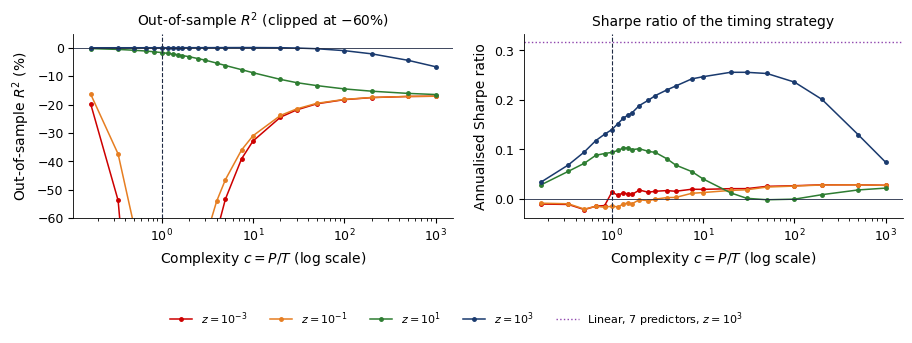

   saved ch14_kmz_complexity


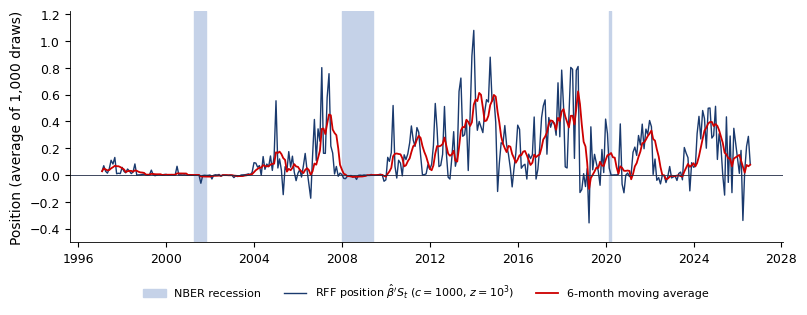

   saved ch14_kmz_positions
            r2     sr      t     ir   ir_t  maxloss    skew  ir_lin  ir_lin_t
lin0 -1536.465 -0.064 -0.348 -0.020 -0.105   17.386 -14.748     NaN       NaN
lin3     0.254  0.317  1.718  0.245  1.312    6.644   0.331     NaN       NaN
rff     -6.678  0.074  0.401 -0.175 -0.936    6.991   0.062   0.027     0.144
{'long_share': 72.23796033994334, 'mean': 0.1345375502093955, 'rec': -0.006104470905008327, 'pre': 0.0743404173432207, 'other': 0.15089430911100607, 'n_rec': 3, 'rec_start': ['2001-04', '2008-01', '2020-03']}
Out-of-sample R-squared (%): all computed grid points, including values outside the plotted range
log10 z            -3       -2       -1       0       1       2      3
c = P/T                                                               
0.166667      -19.728  -19.368  -16.301  -5.348  -0.284   0.005  0.003
0.333333      -53.791  -51.330  -37.443 -10.078  -0.576   0.010  0.008
0.500000     -117.995 -105.981  -62.970 -14.286  -0.883   0.010  0.01

In [ ]:
out = kmz_run()
fig_kmz_complexity(out)
fig_kmz_positions(out)
print(pd.DataFrame(kmz_table(out)).T.round(3))
print(kmz_positions_stats(out))
for metric, label, scale in [('r2', 'Out-of-sample R-squared (%)', 100), ('sr', 'Annualised Sharpe ratio', 1)]:
    print(label + ': all computed grid points, including values outside the plotted range')
    print(pd.DataFrame(scale * out['acc'][metric], index=np.asarray(KMZ_P) / KMZ_T, columns=KMZ_LOGZ).rename_axis(index='c = P/T', columns='log10 z').round(3).to_string())

![ch14_kmz_complexity](./ch14_kmz_complexity.png)

Output: `ch14_kmz_complexity.pdf`

![ch14_kmz_positions](./ch14_kmz_positions.png)

Output: `ch14_kmz_positions.pdf`